In [1]:
'''Optimize complex machine learning models using Bayesian optimization, leveraging probabilistic models
 to identify optimal hyperparameter settings with minimal iterations.'''

'Optimize complex machine learning models using Bayesian optimization, leveraging probabilistic models\n to identify optimal hyperparameter settings with minimal iterations.'

In [2]:
# import data manipulation and visualization libraries
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# import scikit learn and bayesian optimization modules
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score
from skopt import BayesSearchCV

In [4]:
# load dataset from csv file
df = pd.read_csv('Adm.csv')

In [5]:
# inspect dataset information and dimensions
print('dataset shape:', df.shape)
print('first 3 rows:')
print(df.head(3))

dataset shape: (1000, 12)
first 3 rows:
   Serial No.  GRE Score  ...                             University_Name  region
0           1        337  ...    Indian Institute of Technology Kharagpur    East
1           2        324  ...  National Institute of Technology Karnataka   South
2           3        316  ...                          Gujarat University    West

[3 rows x 12 columns]


In [6]:
# inspect statistical summary of numerical features
print('statistical summary:')
print(df.describe().round(2))

statistical summary:
       Serial No.  GRE Score  TOEFL Score  ...     CGPA  Research  Chance of Admit
count     1000.00    1000.00      1000.00  ...  1000.00    1000.0          1000.00
mean       500.50     315.96       106.56  ...     8.59       0.5             0.72
std        288.82      13.42         7.63  ...     0.61       0.5             0.11
min          1.00     290.00        92.00  ...     6.77       0.0             0.39
25%        250.75     305.00       101.00  ...     8.18       0.0             0.65
50%        500.50     316.00       107.00  ...     8.58       1.0             0.71
75%        750.25     326.25       113.00  ...     9.07       1.0             0.79
max       1000.00     340.00       120.00  ...     9.95       1.0             0.99

[8 rows x 9 columns]


In [7]:
# check for missing values in dataset
missing_summary = df.isnull().sum()
print('missing values per column:')
print(missing_summary)

missing values per column:
Serial No.              0
GRE Score               0
TOEFL Score             0
University Rating       0
SOP                     0
LOR                     0
CGPA                    0
Research                0
Chance of Admit         0
Application_DateTime    0
University_Name         0
region                  0
dtype: int64


In [8]:
# select input features and target variable
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = 'Chance of Admit'

X = df[features]
y = df[target]

print('selected features:', features)
print('target variable:', target)

selected features: ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target variable: Chance of Admit


In [9]:
# split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('training set samples:', len(X_train))
print('testing set samples:', len(X_test))

training set samples: 800
testing set samples: 200


In [10]:
# train baseline model before optimization
baseline_model = GradientBoostingRegressor(random_state=42)
baseline_model.fit(X_train, y_train)

print('baseline model trained successfully')

baseline model trained successfully


In [11]:
# evaluate baseline model performance on test set
baseline_pred = baseline_model.predict(X_test)

baseline_r2 = r2_score(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = root_mean_squared_error(y_test, baseline_pred)
baseline_mae = mean_absolute_error(y_test, baseline_pred)

print('baseline r2 score:', round(baseline_r2, 4))
print('baseline mse:', round(baseline_mse, 6))
print('baseline rmse:', round(baseline_rmse, 4))
print('baseline mae:', round(baseline_mae, 4))

baseline r2 score: 0.9268
baseline mse: 0.000749
baseline rmse: 0.0274
baseline mae: 0.0214


In [12]:
# define complex model and hyperparameter search space
complex_model = GradientBoostingRegressor(random_state=42)

search_spaces = {
    'n_estimators': (50, 150),
    'learning_rate': (0.01, 0.2, 'log-uniform'),
    'max_depth': (2, 6),
    'subsample': (0.7, 1.0, 'uniform'),
    'min_samples_split': (2, 8),
    'min_samples_leaf': (1, 4)
}

print('probabilistic search spaces defined across 6 hyperparameters')

probabilistic search spaces defined across 6 hyperparameters


In [13]:
# configure and execute bayesian optimization using gaussian process
bayes_opt = BayesSearchCV(
    estimator=complex_model,
    search_spaces=search_spaces,
    n_iter=15,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=1
)

start_time = time.time()
bayes_opt.fit(X_train, y_train)
bayes_time = time.time() - start_time

print('bayesian optimization completed in:', round(bayes_time, 2), 'seconds')
print('best cross validation r2 score:', round(bayes_opt.best_score_, 4))

bayesian optimization completed in: 9.33 seconds
best cross validation r2 score: 0.9339


In [14]:
# extract optimal hyperparameter settings found by bayesian optimization
print('optimal hyperparameter settings identified:')
for param, val in bayes_opt.best_params_.items():
    print(f'  {param}: {val}')

iteration_scores = bayes_opt.cv_results_['mean_test_score']
print('total iterations evaluated:', len(iteration_scores))
print('best iteration number:', np.argmax(iteration_scores) + 1)

optimal hyperparameter settings identified:
  learning_rate: 0.042669890501344655
  max_depth: 2
  min_samples_leaf: 4
  min_samples_split: 2
  n_estimators: 150
  subsample: 0.7
total iterations evaluated: 15
best iteration number: 11


In [15]:
# evaluate best optimized model on test set
best_model = bayes_opt.best_estimator_
opt_pred = best_model.predict(X_test)

opt_r2 = r2_score(y_test, opt_pred)
opt_mse = mean_squared_error(y_test, opt_pred)
opt_rmse = root_mean_squared_error(y_test, opt_pred)
opt_mae = mean_absolute_error(y_test, opt_pred)

print('optimized model test r2:', round(opt_r2, 4))
print('optimized model test mse:', round(opt_mse, 6))
print('optimized model test rmse:', round(opt_rmse, 4))
print('optimized model test mae:', round(opt_mae, 4))

optimized model test r2: 0.9209
optimized model test mse: 0.00081
optimized model test rmse: 0.0285
optimized model test mae: 0.0223


In [16]:
# compare baseline model versus bayesian optimized model
comparison_summary = pd.DataFrame({
    'metric': ['r2 score', 'mean squared error', 'root mean squared error', 'mean absolute error'],
    'baseline_model': [baseline_r2, baseline_mse, baseline_rmse, baseline_mae],
    'bayesian_optimized_model': [opt_r2, opt_mse, opt_rmse, opt_mae]
})

print('model comparison summary:')
print(comparison_summary.to_string(index=False))

model comparison summary:
                 metric  baseline_model  bayesian_optimized_model
               r2 score        0.926820                  0.920862
     mean squared error        0.000749                  0.000810
root mean squared error        0.027372                  0.028464
    mean absolute error        0.021355                  0.022349


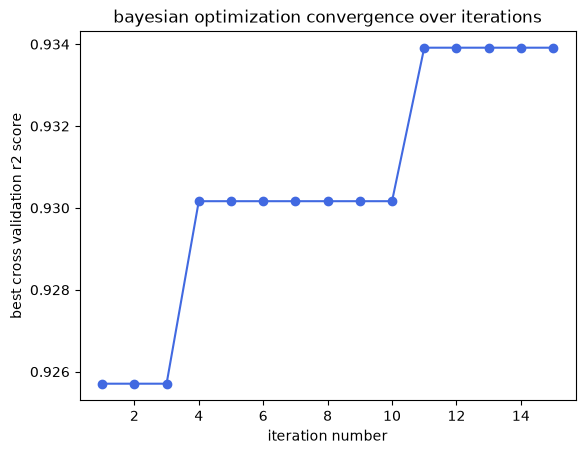

In [17]:
# plot bayesian optimization convergence across minimal iterations
cumulative_best = np.maximum.accumulate(iteration_scores)
plt.plot(range(1, len(cumulative_best) + 1), cumulative_best, marker='o', color='royalblue')
plt.title('bayesian optimization convergence over iterations')
plt.xlabel('iteration number')
plt.ylabel('best cross validation r2 score')
plt.show()

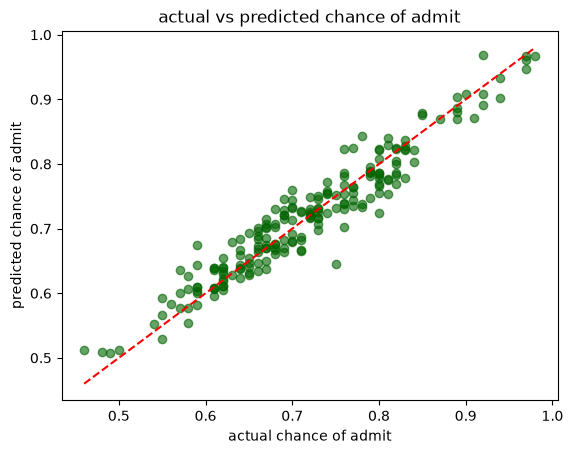

In [18]:
# plot actual versus predicted values for optimized model
plt.scatter(y_test, opt_pred, color='darkgreen', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
plt.title('actual vs predicted chance of admit')
plt.xlabel('actual chance of admit')
plt.ylabel('predicted chance of admit')
plt.show()